# What Drives YouTube Views? A Regression Analysis

**Question:** Which factors are linked to a video getting more views, and how well can we predict views?

**Data:** 17,589 YouTube videos (`youtube.xlsx`) with category, length, resolution, likes, comments and views.

**Steps**
1. Load and check the data
2. Split into 80% training and 20% test data **before** any analysis (the test data is only used for final scoring)
3. Explore the training data with charts
4. Set a simple baseline: guess the median views for every video
5. Build two linear regression models
   - **Model A:** category, length, resolution, likes and comments (which factors matter most?)
   - **Model B:** only information known before upload: category, length, resolution
6. Compare both models with the baseline on the test data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
BLUE = "#2a6fdb"
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and check the data

In [2]:
df = pd.read_excel("../data/youtube.xlsx")

cols = ["category", "duration", "height", "likes", "comments", "views"]
df = df[cols]

print("Rows, columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Videos with 0 views:", (df["views"] == 0).sum())
df.describe()

Rows, columns: (17589, 6)
Missing values: 0
Videos with 0 views: 171


,duration,height,likes,comments,views
count,"17,589.00","17,589.00","17,589.00","17,589.00","17,589.00"
mean,241.55,766.78,208.86,12.90,"68,941.58"
std,493.03,467.29,"8,477.50",225.84,"3,537,491.15"
min,1.00,108.00,0.00,0.00,0.00
25%,51.00,426.00,0.00,0.00,38.00
50%,135.00,640.00,1.00,0.00,152.00
75%,268.00,960.00,4.00,1.00,800.00
max,"25,845.00","2,592.00","836,981.00","16,634.00","410,384,910.00"


**Note:** the median video has about 150 views, but the mean is about 69,000. A few viral videos pull the average up a lot.
So the data is very skewed, and the median is a better "typical" number than the mean.

`height` is the video resolution (for example 720 = 720p).

## 2. Split the data first (80% train / 20% test)

In [3]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print("Training videos:", len(train))
print("Test videos:", len(test))

Training videos: 14071
Test videos: 3518


All charts and model fitting below use **only the training data**. The test data stays hidden until the final scoring in step 6.

## 3. Explore the training data

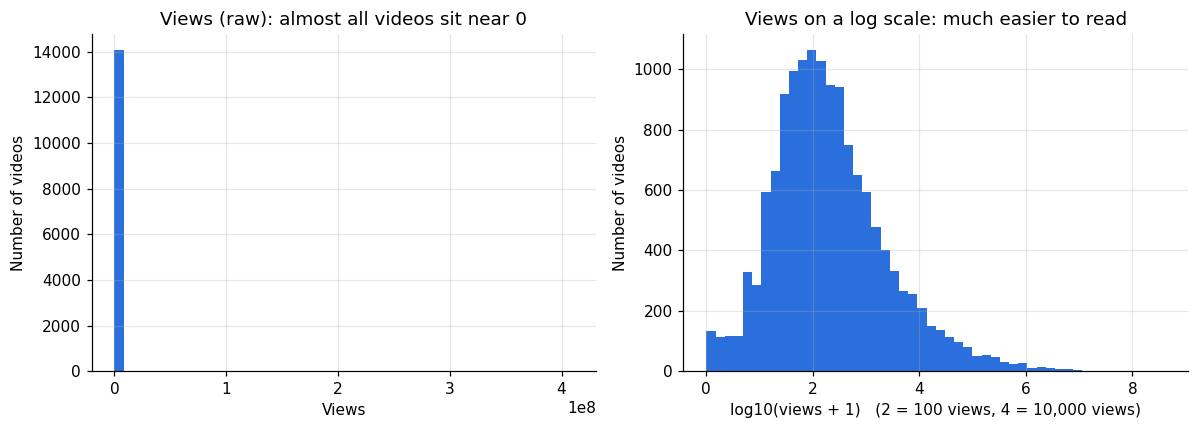

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(train["views"], bins=50, color=BLUE)
axes[0].set_title("Views (raw): almost all videos sit near 0")
axes[0].set_xlabel("Views")
axes[0].set_ylabel("Number of videos")

axes[1].hist(np.log10(train["views"] + 1), bins=50, color=BLUE)
axes[1].set_title("Views on a log scale: much easier to read")
axes[1].set_xlabel("log10(views + 1)   (2 = 100 views, 4 = 10,000 views)")
axes[1].set_ylabel("Number of videos")

plt.tight_layout()
plt.show()

Raw views are extremely skewed. On a log scale they look close to a bell curve.
That is why the models below predict **log(views)** instead of raw views. It stops a handful of viral videos from dominating the model.

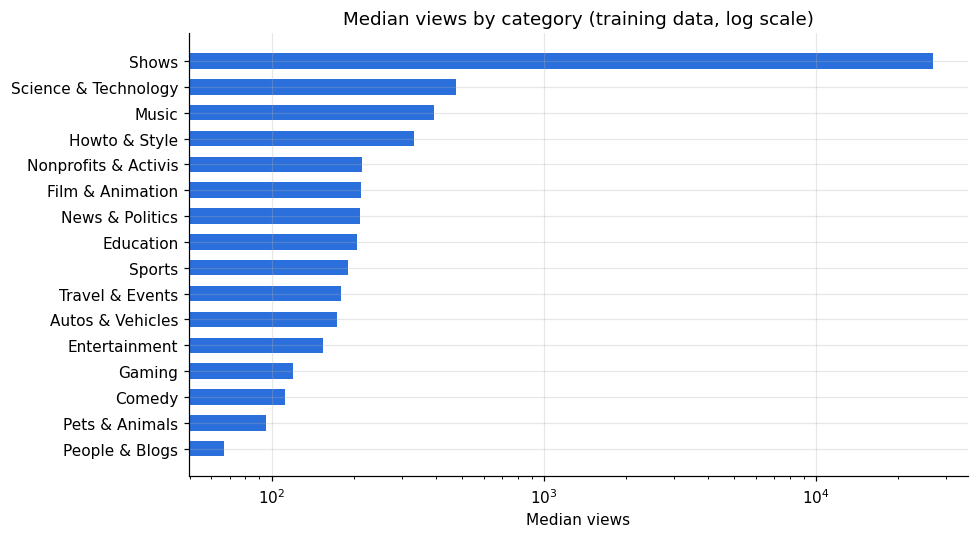

Science & Technology    220
Nonprofits & Activis    175
Shows                    12
Name: category, dtype: int64


In [5]:
cat_median = train.groupby("category")["views"].median().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(cat_median.index, cat_median.values, color=BLUE, height=0.6)
plt.xscale("log")
plt.title("Median views by category (training data, log scale)")
plt.xlabel("Median views")
plt.tight_layout()
plt.show()

print(train["category"].value_counts().tail(3))

Music and Science & Technology videos get more views than People & Blogs.
"Shows" looks very high, but it has only a handful of videos, so that number is not reliable.

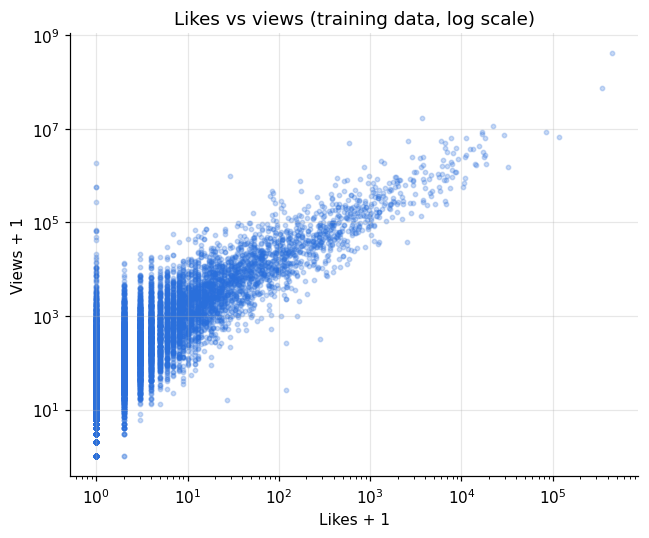

Correlation of log(likes) and log(views): 0.82


In [6]:
plt.figure(figsize=(6, 5))
plt.scatter(train["likes"] + 1, train["views"] + 1, s=8, alpha=0.25, color=BLUE)
plt.xscale("log")
plt.yscale("log")
plt.title("Likes vs views (training data, log scale)")
plt.xlabel("Likes + 1")
plt.ylabel("Views + 1")
plt.tight_layout()
plt.show()

print("Correlation of log(likes) and log(views):",
      round(np.corrcoef(np.log1p(train["likes"]), np.log1p(train["views"]))[0, 1], 2))

Likes and views move together very closely. But likes only exist **after** a video is published, so they explain views rather than predict them ahead of time.

## 4. Prepare features and set the baseline

- Count columns (likes, comments, duration) are also log-transformed because they are skewed too.
- Category becomes 0/1 dummy columns.
- **Baseline:** predict the training median for every test video. Any useful model must beat this.

In [7]:
def make_features(data, numeric_cols):
    X = pd.DataFrame(index=data.index)
    for col in numeric_cols:
        if col in ["likes", "comments", "duration"]:
            X["log_" + col] = np.log1p(data[col])
        else:
            X[col] = data[col]
    dummies = pd.get_dummies(data["category"], prefix="cat", dtype=int)
    return X.join(dummies)

y_train = np.log1p(train["views"])
y_test = np.log1p(test["views"])

baseline_pred = np.full(len(test), y_train.median())
print("Baseline guess for every video:", round(np.expm1(y_train.median())), "views")

Baseline guess for every video: 152 views


## 5. Build two models

In [8]:
features_A = ["likes", "comments", "duration", "height"]   # includes engagement
features_B = ["duration", "height"]                        # known before upload

X_train_A = make_features(train, features_A)
X_test_A = make_features(test, features_A).reindex(columns=X_train_A.columns, fill_value=0)
X_train_B = make_features(train, features_B)
X_test_B = make_features(test, features_B).reindex(columns=X_train_B.columns, fill_value=0)

model_A = LinearRegression().fit(X_train_A, y_train)
model_B = LinearRegression().fit(X_train_B, y_train)

pred_A = model_A.predict(X_test_A)
pred_B = model_B.predict(X_test_B)

## 6. Score on the test data

In [9]:
def within_2x(pred_log, actual_log):
    # share of videos where the prediction is within 2x of the real views
    pred, actual = np.expm1(pred_log) + 1, np.expm1(actual_log) + 1
    ratio = np.maximum(pred, actual) / np.minimum(pred, actual)
    return (ratio <= 2).mean()

base_mae = mean_absolute_error(y_test, baseline_pred)
results = []
for name, pred in [("Baseline (median guess)", baseline_pred),
                   ("Model A: with likes & comments", pred_A),
                   ("Model B: before-upload info only", pred_B)]:
    mae = mean_absolute_error(y_test, pred)
    results.append({
        "Model": name,
        "R² (log views)": r2_score(y_test, pred),
        "Avg error (log views)": mae,
        "Error vs baseline": f"{(mae - base_mae) / base_mae:+.0%}",
        "Within 2x of real views": f"{within_2x(pred, y_test):.0%}",
    })

results = pd.DataFrame(results).set_index("Model")
results

,R² (log views),Avg error (log views),Error vs baseline,Within 2x of real views
Model,,,,
Baseline (median guess),-0.02,1.95,+0%,24%
Model A: with likes & comments,0.69,1.10,-43%,40%
Model B: before-upload info only,0.11,1.83,-6%,25%


**How to read this table**
- **R²:** share of the ups and downs in (log) views the model explains. 0 = no better than a flat guess, 1 = perfect.
- **Avg error (log views):** lower is better. "Error vs baseline" shows how much smaller it is than the median guess.
- **Within 2x:** share of test videos where the prediction lands between half and double the real views.

Model A, engagement and video features:
log_likes       1.23
log_comments    0.06
log_duration    0.11
height         -0.00
dtype: float64


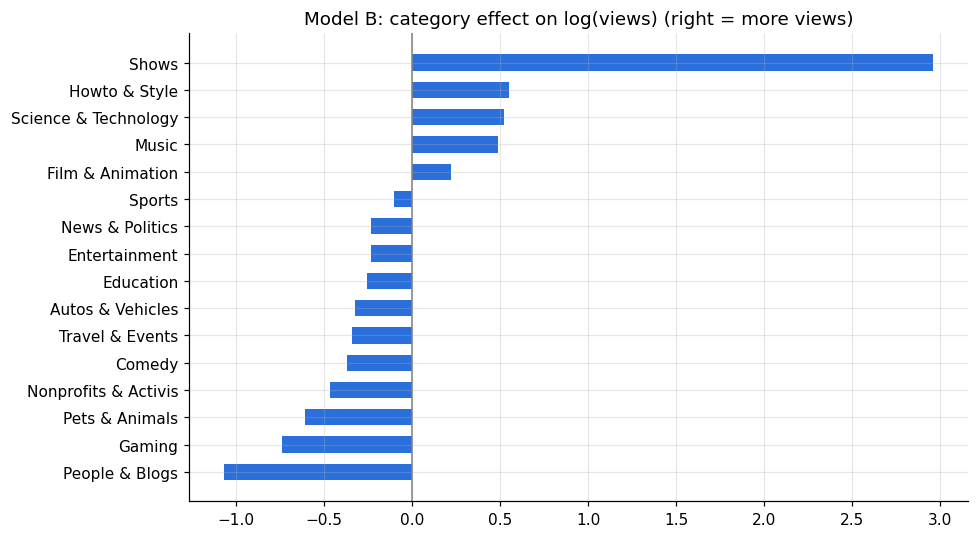

In [10]:
coef_A = pd.Series(model_A.coef_, index=X_train_A.columns)
print("Model A, engagement and video features:")
print(coef_A[[c for c in coef_A.index if not c.startswith("cat_")]].round(3))

coef_B = pd.Series(model_B.coef_, index=X_train_B.columns)
cat_coef = coef_B[[c for c in coef_B.index if c.startswith("cat_")]].sort_values()
plt.figure(figsize=(9, 5))
plt.barh(cat_coef.index.str.replace("cat_", ""), cat_coef.values, color=BLUE, height=0.6)
plt.axvline(cat_coef.mean(), color="gray", linewidth=1)
plt.title("Model B: category effect on log(views) (right = more views)")
plt.tight_layout()
plt.show()

## 7. Conclusion

**Findings**
1. **Likes are by far the strongest factor.** Model A explains about 69% of the variation in (log) views on unseen test videos, and its average error is 43% lower than the baseline. Roughly, 10% more likes goes with about 12% more views.
2. **Before-upload information alone predicts views poorly.** Model B (category, length, resolution) cuts the error by only 6% versus the baseline (R² = 0.11). Category matters somewhat; length and resolution matter very little.
3. **So, to predict views before publishing, this data is not enough.** Things like channel size, title, thumbnail and upload time would likely be needed.

**Limitations**
- Likes and views are recorded at the same time, so Model A shows a strong link, not cause and effect.
- Some categories (for example Shows) have very few videos, so their results are not reliable.
- This is one snapshot of videos, not views tracked over time.